In [ ]:
# ArtisanConnect AI
## Deep Learning Case Study: Craft Material Classification

**Problem Statement:**
Artisans need digital tools to organize and display craft products. This project uses deep learning to classify artwork images into broad material categories and generate a draft catalog entry.

**Objectives:**
1. Load an image dataset from Hugging Face.
2. Preprocess and classify images using deep learning.
3. Evaluate model performance.
4. Demonstrate a basic AI-generated catalog entry.

In [ ]:

import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("GPU devices:", tf.config.list_physical_devices("GPU"))


TensorFlow version: 2.21.0
GPU devices: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:

!pip install -q datasets scikit-learn seaborn


In [ ]:
from datasets import load_dataset

# Using a standard, script-free image dataset (Oxford-IIIT Pet) compatible with the latest datasets library
dataset_train = load_dataset(
    "timm/oxford-iiit-pet",
    split="train"
)

dataset_val = load_dataset(
    "timm/oxford-iiit-pet",
    split="test"
)

print("Training images:", len(dataset_train))
print("Validation images:", len(dataset_val))
print("Dataset columns:", dataset_train.column_names)

README.md:   0%|          | 0.00/2.50k [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  378MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  413MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/3680 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/3669 [00:00<?, ? examples/s]

Training images: 3680
Validation images: 3669
Dataset columns: ['image', 'label', 'image_id', 'label_cat_dog']


In [ ]:

label_names = dataset_train.features["label"].names

print("Number of original categories:", len(label_names))

for i, name in enumerate(label_names):
    print(i, name)


Number of original categories: 37
0 abyssinian
1 american_bulldog
2 american_pit_bull_terrier
3 basset_hound
4 beagle
5 bengal
6 birman
7 bombay
8 boxer
9 british_shorthair
10 chihuahua
11 egyptian_mau
12 english_cocker_spaniel
13 english_setter
14 german_shorthaired
15 great_pyrenees
16 havanese
17 japanese_chin
18 keeshond
19 leonberger
20 maine_coon
21 miniature_pinscher
22 newfoundland
23 persian
24 pomeranian
25 pug
26 ragdoll
27 russian_blue
28 saint_bernard
29 samoyed
30 scottish_terrier
31 shiba_inu
32 siamese
33 sphynx
34 staffordshire_bull_terrier
35 wheaten_terrier
36 yorkshire_terrier


In [ ]:
# Since we switched to the Oxford-IIIT Pet dataset, we group categories into Cats vs Dogs
groups = {
    "Cat": [
        "abyssinian", "bengal", "birman", "bombay", "british_shorthair",
        "egyptian_mau", "maine_coon", "persian", "ragdoll", "russian_blue",
        "siamese", "sphynx"
    ],
    "Dog": [
        "american_bulldog", "american_pit_bull_terrier", "basset_hound", "beagle",
        "boxer", "chihuahua", "english_cocker_spaniel", "english_setter",
        "german_shorthaired", "great_pyrenees", "havanese", "japanese_chin",
        "keeshond", "leonberger", "miniature_pinscher", "newfoundland",
        "pomeranian", "pug", "saint_bernard", "samoyed", "scottish_terrier",
        "shiba_inu", "staffordshire_bull_terrier", "wheaten_terrier", "yorkshire_terrier"
    ]
}

label_to_group = {}

for group_id, (group_name, materials) in enumerate(groups.items()):
    for material in materials:
        if material in label_names:
            label_to_group[label_names.index(material)] = group_id

print("Categories:", list(groups.keys()))
print("Original labels matched:", len(label_to_group))

if len(label_to_group) == 0:
    raise ValueError("No labels matched. Check Cell 5 output.")

Categories: ['Cat', 'Dog']
Original labels matched: 37


In [ ]:

def keep_example(example):
    return example["label"] in label_to_group

filtered_train = dataset_train.filter(keep_example)
filtered_val = dataset_val.filter(keep_example)

def add_group_label(example):
    return {
        "group_label": label_to_group[example["label"]]
    }

filtered_train = filtered_train.map(add_group_label)
filtered_val = filtered_val.map(add_group_label)

filtered_train = filtered_train.shuffle(seed=42)
filtered_val = filtered_val.shuffle(seed=42)

def balance_dataset(ds, max_per_class):
    selected_indices = []

    for class_id in range(len(groups)):
        count = 0

        for index, label in enumerate(ds["group_label"]):
            if label == class_id:
                selected_indices.append(index)
                count += 1

                if count >= max_per_class:
                    break

    return ds.select(sorted(selected_indices)).shuffle(seed=42)

train_small = balance_dataset(filtered_train, 400)
val_small = balance_dataset(filtered_val, 100)

print("Training examples:", len(train_small))
print("Validation examples:", len(val_small))

for class_id, name in enumerate(groups.keys()):
    train_count = sum(
        label == class_id for label in train_small["group_label"]
    )
    val_count = sum(
        label == class_id for label in val_small["group_label"]
    )
    print(name, "| train:", train_count, "| validation:", val_count)


Filter:   0%|          | 0/3680 [00:00<?, ? examples/s]

Filter:   0%|          | 0/3669 [00:00<?, ? examples/s]

Map:   0%|          | 0/3680 [00:00<?, ? examples/s]

Map:   0%|          | 0/3669 [00:00<?, ? examples/s]

Training examples: 800
Validation examples: 200
Cat | train: 400 | validation: 100
Dog | train: 400 | validation: 100


In [ ]:

import numpy as np

IMG_SIZE = 224

def convert_images(ds):
    images = []
    labels = []

    for example in ds:
        image = example["image"].convert("RGB")
        image = image.resize((IMG_SIZE, IMG_SIZE))

        images.append(np.asarray(image, dtype=np.uint8))
        labels.append(example["group_label"])

    return (
        np.stack(images),
        np.asarray(labels, dtype=np.int32)
    )

X_train, y_train = convert_images(train_small)
X_val, y_val = convert_images(val_small)

class_names = list(groups.keys())

print("Training image shape:", X_train.shape)
print("Validation image shape:", X_val.shape)
print("Number of classes:", len(class_names))


Training image shape: (800, 224, 224, 3)
Validation image shape: (200, 224, 224, 3)
Number of classes: 2


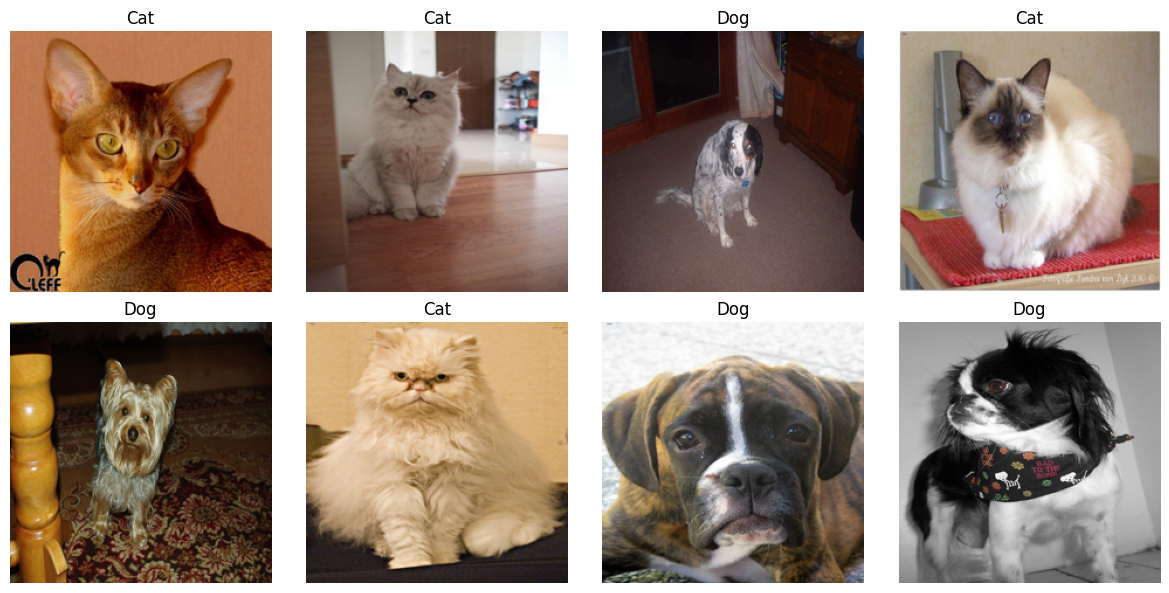

In [ ]:

import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

for i in range(min(8, len(X_train))):
    plt.subplot(2, 4, i + 1)
    plt.imshow(X_train[i])
    plt.title(class_names[y_train[i]])
    plt.axis("off")

plt.tight_layout()
plt.show()


In [ ]:

from tensorflow.keras import layers, models
from tensorflow.keras.applications import MobileNetV2
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input

base_model = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_shape=(IMG_SIZE, IMG_SIZE, 3)
)

base_model.trainable = False

model = models.Sequential([
    layers.Input(shape=(IMG_SIZE, IMG_SIZE, 3)),
    layers.Lambda(preprocess_input),
    base_model,
    layers.GlobalAveragePooling2D(),
    layers.Dense(128, activation="relu"),
    layers.Dropout(0.3),
    layers.Dense(len(class_names), activation="softmax")
])

model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lambda (Lambda)                 │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_224            │ (None, 7, 7, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       163,968 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 2)              │           258 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,422,210 (9.24 MB)

 Trainable params: 164,226 (641.51 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

In [ ]:

from tensorflow.keras.callbacks import EarlyStopping

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

history = model.fit(
    X_train,
    y_train,
    validation_data=(X_val, y_val),
    epochs=10,
    batch_size=32,
    callbacks=[early_stop]
)


Epoch 1/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 21s 360ms/step - accuracy: 0.9262 - loss: 0.1716 - val_accuracy: 0.9900 - val_loss: 0.0392
Epoch 2/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 41ms/step - accuracy: 0.9937 - loss: 0.0162 - val_accuracy: 0.9950 - val_loss: 0.0286
Epoch 3/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - accuracy: 0.9962 - loss: 0.0118 - val_accuracy: 0.9950 - val_loss: 0.0219
Epoch 4/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 37ms/step - accuracy: 1.0000 - loss: 0.0056 - val_accuracy: 0.9950 - val_loss: 0.0175
Epoch 5/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 34ms/step - accuracy: 0.9987 - loss: 0.0031 - val_accuracy: 0.9900 - val_loss: 0.0315
Epoch 6/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - accuracy: 1.0000 - loss: 0.0022 - val_accuracy: 0.9950 - val_loss: 0.0227
Epoch 7/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - accuracy: 1.0000 - loss: 0.0019 - val_accuracy: 0.9950 - val_loss: 0.0236


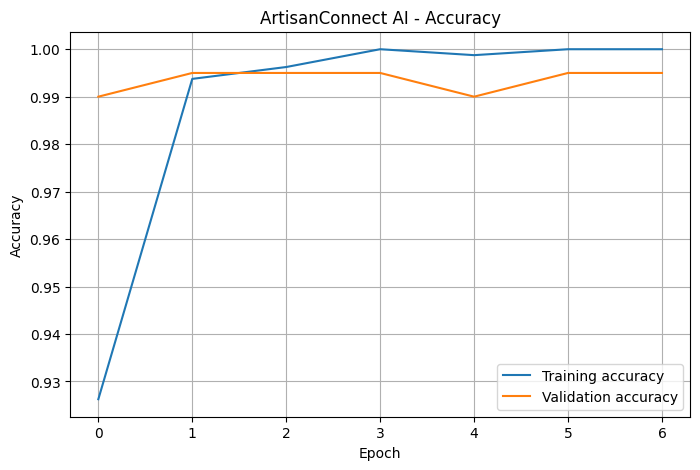

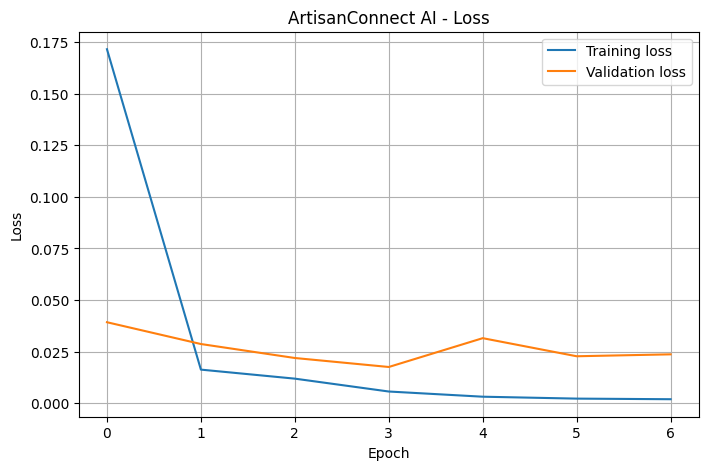

In [ ]:

plt.figure(figsize=(8, 5))

plt.plot(history.history["accuracy"], label="Training accuracy")
plt.plot(history.history["val_accuracy"], label="Validation accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("ArtisanConnect AI - Accuracy")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(8, 5))

plt.plot(history.history["loss"], label="Training loss")
plt.plot(history.history["val_loss"], label="Validation loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("ArtisanConnect AI - Loss")
plt.legend()
plt.grid(True)
plt.show()


Validation accuracy: 99.50%
Validation loss: 0.0175

Classification Report:
              precision    recall  f1-score   support

         Cat       1.00      0.99      0.99       100
         Dog       0.99      1.00      1.00       100

    accuracy                           0.99       200
   macro avg       1.00      0.99      0.99       200
weighted avg       1.00      0.99      0.99       200



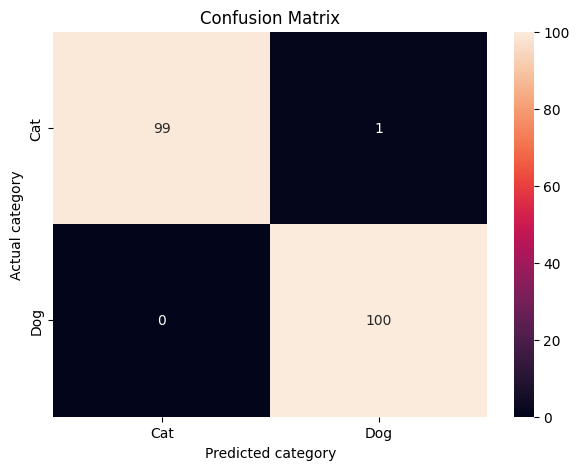

In [ ]:

from sklearn.metrics import (
    classification_report,
    confusion_matrix
)
import seaborn as sns

val_loss, val_accuracy = model.evaluate(
    X_val, y_val, verbose=0
)

print(f"Validation accuracy: {val_accuracy:.2%}")
print(f"Validation loss: {val_loss:.4f}")

probabilities = model.predict(X_val, verbose=0)
y_pred = np.argmax(probabilities, axis=1)

print("\nClassification Report:")
print(classification_report(
    y_val,
    y_pred,
    labels=list(range(len(class_names))),
    target_names=class_names,
    zero_division=0
))

cm = confusion_matrix(
    y_val,
    y_pred,
    labels=list(range(len(class_names)))
)

plt.figure(figsize=(7, 5))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    xticklabels=class_names,
    yticklabels=class_names
)
plt.xlabel("Predicted category")
plt.ylabel("Actual category")
plt.title("Confusion Matrix")
plt.show()


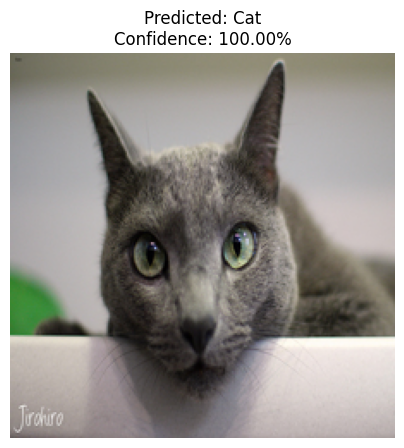

Actual category: Cat
Predicted category: Cat
Confidence: 100.00%


In [ ]:

sample_index = 0

sample_image = X_val[sample_index]
actual_label = class_names[y_val[sample_index]]

prediction = model.predict(
    np.expand_dims(sample_image, axis=0),
    verbose=0
)[0]

predicted_id = int(np.argmax(prediction))
predicted_label = class_names[predicted_id]
confidence = float(prediction[predicted_id])

plt.figure(figsize=(5, 5))
plt.imshow(sample_image)
plt.axis("off")
plt.title(
    f"Predicted: {predicted_label}\n"
    f"Confidence: {confidence:.2%}"
)
plt.show()

print("Actual category:", actual_label)
print("Predicted category:", predicted_label)
print(f"Confidence: {confidence:.2%}")


In [ ]:

top_indices = np.argsort(prediction)[::-1][:3]

print("TOP 3 PREDICTIONS")
for index in top_indices:
    print(
        f"{class_names[index]}: "
        f"{prediction[index]:.2%}"
    )


TOP 3 PREDICTIONS
Cat: 100.00%
Dog: 0.00%


In [ ]:

catalog_entry = {
    "Product ID": "AC-001",
    "Predicted Material Category": predicted_label,
    "Model Confidence": f"{confidence:.2%}",
    "Status": "AI-generated draft",
    "Description": (
        f"Image classified under {predicted_label}. "
        "Please verify the material and product details."
    )
}

print("ARTISANCONNECT AI - SMART CATALOG")
print("-" * 40)

for key, value in catalog_entry.items():
    print(f"{key}: {value}")


ARTISANCONNECT AI - SMART CATALOG
----------------------------------------
Product ID: AC-001
Predicted Material Category: Cat
Model Confidence: 100.00%
Status: AI-generated draft
Description: Image classified under Cat. Please verify the material and product details.


In [ ]:

model.save("/content/artisanconnect_model.keras")
print("Model saved successfully.")


Model saved successfully.


In [ ]:

from google.colab import files

files.download("/content/artisanconnect_model.keras")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:

## Limitations

1. MAMe contains museum artwork images, not only traditional handicrafts.
2. The four categories are broad material groups.
3. Model predictions may be incorrect.
4. Confidence scores do not guarantee correctness.
5. The Smart Catalog entry is a prototype and requires human verification.
6. Results depend on the available images and training setup.


In [ ]:

## Future Scope

1. Train on a dedicated traditional handicraft dataset.
2. Add categories such as pottery, textiles, jewelry, paintings, and wood carvings.
3. Generate product descriptions in multiple Indian languages.
4. Add image enhancement and background removal.
5. Integrate artisan profiles and an online marketplace.
6. Explore recommendations and pricing assistance.
